# t-SNE vs UMAP on 3-D Clusters

Four 3-D Gaussian clusters with different spreads, reduced to 2-D with t-SNE and UMAP to compare how each method preserves local and global structure.


In [27]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from umap import UMAP

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

import plotly.express as px
from sklearn.datasets import make_blobs

In [28]:
# CLuster centers:
centers = [ [ 2, -6, -6],
            [-1,  9,  4],
            [-8,  7,  2],
            [ 4,  7,  9] ]

# Cluster standard deviations:
cluster_std=[1,1,2,3.5]

# Make the blobs and return the data and the blob labels
X, labels_ = make_blobs(n_samples=500, centers=centers, n_features=3, cluster_std=cluster_std, random_state=42)

In [29]:
# Create a DataFrame for Plotly
df = pd.DataFrame(X, columns=['X', 'Y', 'Z'])

# Create interactive 3D scatter plot
fig = px.scatter_3d(df, x='X', y='Y', z='Z', color=labels_.astype(str) ,  opacity=0.7,  color_discrete_sequence=px.colors.qualitative.G10, title="3D Scatter Plot of Four Blobs")

fig.update_traces(marker=dict(size=5, line=dict(width=1, color='black')), showlegend=False)
fig.update_layout(coloraxis_showscale=False, width=1000, height=800)  # Remove color bar, resize plot

fig.show()

There are 4 clusters, but they differ a lot in density and separation. Only some of them will be easy to tell apart.

Green is tight and isolated. It's a compact cluster with a small spread, far from the others, so every method should separate it cleanly.
Orange and red are close and partly overlap. Orange is dense and red is a bit wider, and they touch. Expect some mixing at their boundary in any 2-D projection.
Blue is very diffuse. Its points spread across a large region (roughly −10 to 15 on Z) and pass through and near the other clusters. With such a large spread, blue is the hardest group to recover as one cluster.
The clusters have different spreads. In the IBM lab this comes from cluster_std values that differ per cluster (from tight to very wide). This is closer to real data than equal-sized round clusters.

In [33]:
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

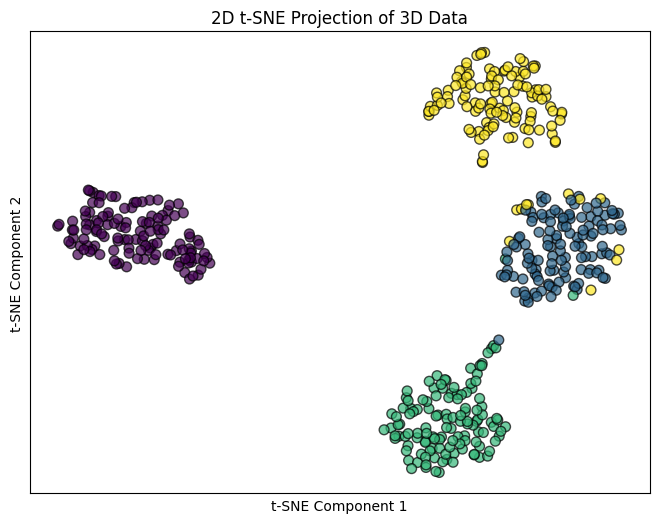

In [34]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=labels_, cmap='viridis', s=50, alpha=0.7, edgecolor='k')
ax.set_title("2D t-SNE Projection of 3D Data")
ax.set_xlabel("t-SNE Component 1")
ax.set_ylabel("t-SNE Component 2")
ax.set_xticks([])
ax.set_yticks([])
plt.show()

All 4 clusters are clearly separated. Each group forms its own island with wide empty space between them. t-SNE preserves local neighbourhoods well: points that were close in 3-D stay together.
Almost every point stays in its own cluster. The exceptions are a few yellow points and one green point that ended up inside the blue-grey cluster. In the 3-D plot, those are the points where clusters touched or overlapped.
The difference in spread disappeared. In 3-D, one cluster was very diffuse and another very tight. Here all 4 look about the same size and density. t-SNE equalizes density, so cluster size in this plot tells you nothing about how spread out the original group was.
The gaps between clusters don't mean anything. In 3-D, two clusters (orange and red) were close neighbours, but here every cluster seems equally far from the others. Distances between clusters in t-SNE are not reliable, and neither is their position on the plot.
The green cluster has a tail (the diagonal stretch toward the top). Tails like this usually come from sparse or boundary points, often from where a diffuse cluster crosses near a denser one.

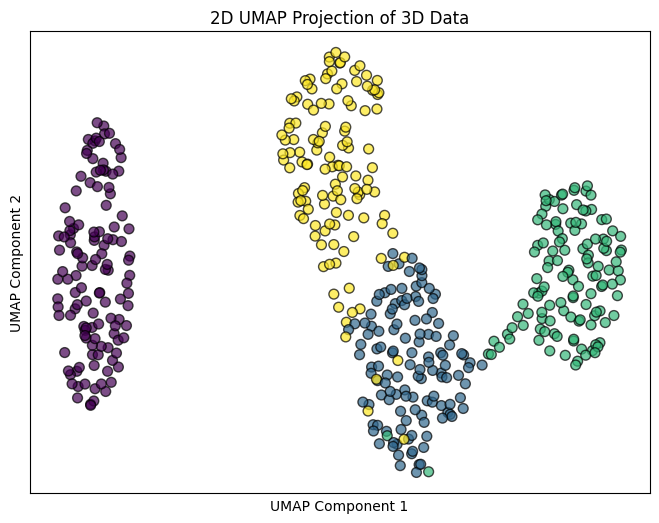

In [ ]:
umap_model = UMAP(n_components=2, random_state=42, min_dist=0.5, spread=1, n_jobs=1)
# Apply UMAP to reduce the dimensionality to 2D


X_umap = umap_model.fit_transform(X_scaled)

# Plot the 2D UMAP projection result 
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111)
ax.scatter(X_umap[:, 0], X_umap[:, 1], c=labels_, cmap='viridis', s=50, alpha=0.7, edgecolor='k')

ax.set_title("2D UMAP Projection of 3D Data")
ax.set_xlabel("UMAP Component 1", )
ax.set_ylabel("UMAP Component 2", )
ax.set_xticks([])
ax.set_yticks([])
plt.show()


Conclusion
The purple cluster is far from the rest. A wide empty gap separates it from the other three, which fits the tight, isolated cluster in the 3-D plot. UMAP keeps that isolation, while t-SNE showed all clusters as equally far apart.

The other three clusters are connected.

Yellow merges into blue-grey. There's no clear gap between them, and several yellow points sit inside the blue-grey cluster.
Green is joined to blue-grey by a thin bridge of points. These are boundary points between two nearby groups.
In 3-D, those three groups were close or overlapping, so UMAP shows the real proximity instead of hiding it.

The spread differs between clusters. Yellow is looser and stretched out, while purple and green are more compact. With min_dist=0.5, UMAP keeps some of the original difference in spread, which t-SNE erased.

Mixed points match the overlap in 3-D. The yellow points inside blue-grey, and the green point at the bottom of blue-grey, are the same kind of boundary cases t-SNE also misplaced. They come from real overlap in the data, not from an error in UMAP.

t-SNE vs UMAP on this data